In [4]:
BATCH = 1  



In [5]:
engine = create_engine("mysql+pymysql://root:root@dq_mariadb:3306/bronze")



NameError: name 'create_engine' is not defined

In [6]:
import pandas as pd
from sqlalchemy import create_engine

engine = create_engine("mysql+pymysql://root:root@dq_mariadb:3306/bronze")
pd.read_sql("SHOW DATABASES;", con=engine)



,Database
0,bronze
1,cif
2,crm
3,crm_cible
4,dq
5,gold
6,information_schema
7,mysql
8,performance_schema
9,silver


In [36]:
contrat = pd.read_sql("""
SELECT souscripteur_id, date_debut, date_fin, date_derniere_cotisation
FROM bronze.crm_contrat
""", con=engine)

for c in ["date_debut", "date_fin", "date_derniere_cotisation"]:
    contrat[c] = pd.to_datetime(contrat[c], errors="coerce")

ref = pd.Timestamp("2024-12-31")  # fecha de referencia
cotisation = ref - pd.Timedelta(days=90)  # últimos 3 meses

# Definiciones
en_cours = (contrat.date_debut <= ref) & (contrat.date_fin >= ref)
n_commerciale = contrat.souscripteur_id.nunique()
n_sinistres = contrat[en_cours].souscripteur_id.nunique()
n_risques = contrat[en_cours & (contrat.date_derniere_cotisation >= cotisation)].souscripteur_id.nunique()

# Tableau des écarts
ecarts = pd.DataFrame({
    "definition": ["Commerciale", "Sinistres", "Risques"],
    "nb": [n_commerciale, n_sinistres, n_risques]
})
ecarts["rapport"] = ecarts.nb / ecarts.nb.max()
ecarts


,definition,nb,rapport
0,Commerciale,50508,1.000000
1,Sinistres,15183,0.300606
2,Risques,14960,0.296191


In [8]:
pd.read_sql("SHOW TABLES FROM bronze;", con=engine)



,Tables_in_bronze
0,cif_clients
1,cif_compte
2,cif_pays
3,crm_client
4,crm_contrat
5,crm_sinistre
6,crm_type_contrat


In [9]:
contrat = pd.read_sql("""
SELECT souscripteur_id, date_debut, date_fin, date_derniere_cotisation
FROM bronze.crm_contrat
""", con=engine)

contrat.head()


,souscripteur_id,date_debut,date_fin,date_derniere_cotisation


In [37]:
for c in ["date_debut", "date_fin", "date_derniere_cotisation"]:
    contrat[c] = pd.to_datetime(contrat[c], errors="coerce")


In [38]:
ref = pd.Timestamp("2024-12-31")  
cotisation = ref - pd.Timedelta(days=90)


In [39]:
n_commerciale = contrat.souscripteur_id.nunique()


In [40]:
en_cours = (contrat.date_debut <= ref) & (contrat.date_fin >= ref)
n_sinistres = contrat[en_cours].souscripteur_id.nunique()


In [41]:
n_risques = contrat[en_cours & (contrat.date_derniere_cotisation >= cotisation)].souscripteur_id.nunique()


In [42]:
ecarts = pd.DataFrame({
    "definition": ["Commerciale", "Sinistres", "Risques"],
    "nb": [n_commerciale, n_sinistres, n_risques]
})
ecarts["rapport"] = ecarts.nb / ecarts.nb.max()
ecarts


,definition,nb,rapport
0,Commerciale,50508,1.000000
1,Sinistres,15183,0.300606
2,Risques,14960,0.296191


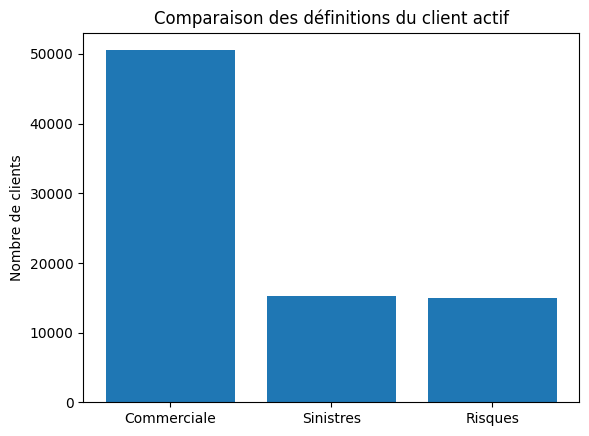

In [43]:
import matplotlib.pyplot as plt

plt.bar(ecarts["definition"], ecarts["nb"])
plt.title("Comparaison des définitions du client actif")
plt.ylabel("Nombre de clients")
plt.show()
